# Gas exchange analysers exhibit large measurement error driven by internal thermal gradients — minimal reproduction

**Paper:** Garen, Branch, Borrego, Blonder, Stinziano & Michaletz (2022) *New Phytologist* 236(2):369–384, DOI [10.1111/nph.18347](https://doi.org/10.1111/nph.18347).

**Author code:** [MichaletzLab/LI-COR-thermal-gradients](https://github.com/MichaletzLab/LI-COR-thermal-gradients) @ commit `15e005fd3797b087429b1ba79183362b4a5cba0e` — per the authors' README, *all figures and statistics may be reproduced by running `R/analysis.R`*.

**Executed scope (one minimal, faithful unit):** this notebook re-runs three author figure scripts on the authors' released trial data, unchanged:

1. **Fig. 2** — reported vs. independently measured in-cuvette **air temperature** (empty chamber), LI-6400XT vs. LI-6800 (`R/make_fig2.R`, `data/licor_trials_all.csv`).
2. **Fig. 5** — **leaf-temperature error** characterised with linear mixed models (`R/make_fig5.R`, `data/Tleaf_error_trials_all.csv`, `nlme::lme`).
3. **Fig. 6** — relative errors in derived quantities (*g*<sub>sw</sub>, *g*<sub>tw</sub>, *g*<sub>tc</sub>, *C*<sub>i</sub>) after applying the authors' instrument-specific **temperature-correction functions** (`R/make_fig6.R`, `data/error_propagation_6400.csv`, `data/error_propagation_6800.csv`, `LICOR6400::calc_licor`).

The associated statistics that the authors `sink()` to `stats.txt` are printed. The paper's headline claims reproduced here: LI-6400XT air-temperature errors up to ≈7.2 °C and leaf-temperature errors up to ≈5.3 °C, while LI-6800 errors are much smaller.

**Omitted scope (not executed here):** Figs. 3–4 (chamber/above–below detail and growth-chamber trials), Figs. 7–8 (assimilation–temperature response fits with `rTPC`/`nls.multstart`, source of the Vcmax 12 % / Jmax 35 % claims), Fig. 9 (A–*C*<sub>i</sub> curves, `plantecophys`), and Supplements S1–S3. This is **not** a full-paper reproduction and not a verification of dataset-level statistics — it validates the released analysis pipeline on the released data for the three figures above.

**Execution status:** executed on a Google Colab **CPU** runtime (no GPU is used anywhere in this method). All data/bytes are downloaded *inside* this notebook from the pinned commit; nothing is bundled.

**日本語:** 本ノートブックは Garen et al. (2022) *New Phytologist* の最小再現です。著者公開の R スクリプト（コミット `15e005f`）をそのまま Colab の CPU ランタイム上で実行し、Fig. 2（空チャンバーでの報告気温 vs 実測気温）、Fig. 5（葉温誤差の混合モデル解析）、Fig. 6（温度補正関数による派生量 g_sw・g_tw・g_tc・C_i の相対誤差）を再現します。Fig. 3–9 の一部と補足図は範囲外です。全データはノートブック内でピン留めしたコミットからダウンロードされます。

## Runtime selection and how to run

**Select a CPU runtime** (`ランタイム → ランタイムのタイプを変更 → CPU`). No GPU is needed: the method is R statistical plotting and linear mixed models (`nlme`), with no GPU kernels. Then **Run all**.

Expected durations measured on a Colab CPU VM (2026-10-29): R package installation ≈ 1–3 min using prebuilt Posit binaries, download + verification a few seconds, mixed-model fits and figure generation well under 2 min. Total ≈ 5–10 min; total downloads < 1 MiB.

**Note:** Colab's Python-kernel runtime is used as a launcher only — all scientific computation runs in **R** via `Rscript`, executing the authors' own script files. Python is not reimplementing any method.
**日本語:** GPU は不要です（R の統計解析・作図のみ）。`ランタイム → ランタイムのタイプを変更 → CPU` を選択してから「すべてのセルを実行」してください。計算はすべて R（`Rscript`）で実行され、Python は起動用ランチャーにすぎません。

### 1. Environment check

Verify that the Colab VM provides the **R** interpreter (`Rscript`) that this notebook drives, and record Python/OS versions for provenance. If `Rscript` is missing, we install Ubuntu's `r-base` package rather than failing silently.
**日本語:** このノートブックが実行に使う R（`Rscript`）が Colab VM にあるか確認し、なければ `r-base` をインストールします。

In [ ]:
import os, subprocess, sys, shutil, json, urllib.request

def run(cmd, timeout=1200):
    env = {**os.environ, "LANG": "C.UTF-8", "LC_ALL": "C.UTF-8"}
    return subprocess.run(cmd, capture_output=True, text=True, timeout=timeout, env=env)

if shutil.which("Rscript") is None:
    print("Rscript not found; installing r-base via apt ...")
    run(["apt-get", "update"], timeout=600)
    r = run(["apt-get", "install", "-y", "--no-install-recommends", "r-base"], timeout=1800)
    if shutil.which("Rscript") is None:
        raise RuntimeError("Could not provision Rscript on this VM")
print("Rscript:", shutil.which("Rscript"))
print(run(["Rscript", "-e", "cat(R.version.string)"]).stdout)
print("OS:", run(["bash", "-c", ". /etc/os-release && echo $VERSION_ID $VERSION_CODENAME"]).stdout.strip())
print("Python:", sys.version.split()[0])

Rscript: /usr/bin/Rscript


R version 4.6.1 (2026-06-24)
OS: 24.04 noble
Python: 3.13.18


### 2. Install required R packages

The selected figure scripts need `ggplot2`, `gridExtra`, `dplyr`, `tidyr` and `nlme` (the last ships with base R distributions, but is ensured here). To avoid slow source compilation on Colab, packages are installed as **prebuilt binaries from the Posit Package Manager** snapshot for this run's date (`2026-10-29`), for the Ubuntu release detected on the VM; if that repo is unreachable the standard CRAN source repo is used as fallback.
**日本語:** 必要な R パッケージを、コンパイル不要の Posit バイナリリポジトリ（実行日のスナップショットに固定）から導入します。失敗時は通常の CRAN ソースにフォールバックします。

In [ ]:
codename = run(["bash", "-c", ". /etc/os-release && echo $VERSION_CODENAME"]).stdout.strip() or "jammy"
snapshot = "2026-10-29"
r_install = f'''
options(warn = 1)
pkgs <- c("ggplot2", "gridExtra", "dplyr", "tidyr", "nlme")
need <- pkgs[!vapply(pkgs, requireNamespace, logical(1), quietly = TRUE)]
if (length(need)) {{
  ok <- FALSE
  binrepo <- "https://packagemanager.posit.co/cran/__linux__/{codename}/{snapshot}"
  ok <- tryCatch({{ install.packages(need, repos = binrepo, quiet = TRUE); TRUE }},
                 error = function(e) FALSE)
  if (!ok || any(!vapply(need, requireNamespace, logical(1), quietly = TRUE))) {{
    install.packages(need, repos = "https://cloud.r-project.org")
  }}
}}
cat("Package versions:\\n")
for (p in pkgs) cat(sprintf("  %-10s %s\\n", p, as.character(packageVersion(p))))
'''
r = run(["Rscript", "-e", r_install], timeout=2400)
print(r.stdout)
if r.returncode != 0:
    print(r.stderr[-3000:])
    raise RuntimeError(f"R package installation failed (exit {r.returncode})")

Package versions:
  ggplot2    4.0.3
  gridExtra  2.3.1
  dplyr      1.2.1
  tidyr      1.3.2
  nlme       3.1.171



### 3. Install the `LICOR6400` package (GitHub)

`correct_licor6400()` calls `calc_licor()`, which recalculates LI-6400XT gas-exchange quantities from raw measured columns. That function lives in the **`LICOR6400`** package by Richard Telford ([Plant-Functional-Trait-Course/LICOR6400](https://github.com/Plant-Functional-Trait-Course/LICOR6400), MIT licence) — it is not on CRAN, which is why it must be installed from GitHub with `remotes`. The package is pure R (no compiled code), so this is quick.
**日本語:** `correct_licor6400()` の内部で使われる `calc_licor()` は CRAN に無い GitHub パッケージ `LICOR6400`（Telford, MIT）に含まれるため、`remotes` 経由でインストールします。

In [ ]:
r_licor = '''
if (!requireNamespace("LICOR6400", quietly = TRUE)) {
  if (!requireNamespace("remotes", quietly = TRUE)) {
    install.packages("remotes", repos = "https://cloud.r-project.org", quiet = TRUE)
  }
  remotes::install_github("Plant-Functional-Trait-Course/LICOR6400", upgrade = "never")
}
cat("LICOR6400 version:", as.character(packageVersion("LICOR6400")), "\\n")
'''
r = run(["Rscript", "-e", r_licor], timeout=1200)
print(r.stdout)
if r.returncode != 0:
    print(r.stderr[-3000:])
    raise RuntimeError("LICOR6400 installation failed")

── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpubRede/remotes4fa2255a47b/Plant-Functional-Trait-Course-LICOR6400-fafad58/DESCRIPTION’ ... OK
* preparing ‘LICOR6400’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
Omitted ‘LazyData’ from DESCRIPTION
* building ‘LICOR6400_0.0.0.9000.tar.gz’

LICOR6400 version: 0.0.0.9000 



### 4. Download the pinned author scripts and trial data (with integrity checks)

All files are fetched **inside the notebook** from `raw.githubusercontent.com` at the pinned commit `15e005f…` of `MichaletzLab/LI-COR-thermal-gradients` and verified two ways: the byte count must equal the size recorded in the GitHub tree API for that commit, and the computed **Git blob SHA-1** (`sha1("blob <size>\\0" + bytes)`) must equal the commit's recorded object hash. A mismatch stops the run rather than continuing with corrupt input. All bytes stay on the Colab VM under `/content`.
**日本語:** 著者リポジトリの R スクリプトと実験データ CSV を、ピン留めしたコミットからノートブック内でダウンロードし、バイト数と Git blob SHA-1 の両方で完全性を検証します（不一致なら停止）。全データは Colab VM の `/content` に置かれます。

In [ ]:
PINNED = {
    "R/analysis.R":               (1629,   "e11185166acc76109aaf32271519eb871eaf3372"),
    "R/correct_licor6400.R":      (1557,   "5ffec4a79a1a3eea4687bb6eb78291b282a42c93"),
    "R/correct_licor6800.R":      (1279,   "6ebb9799c729c8e19d62ff9a6fb71e46c2d823d2"),
    "R/make_fig2.R":              (3142,   "e9524ff5c5636601623770b13305363f6972d4ad"),
    "R/make_fig5.R":              (6730,   "b142d31b73718a150cb1cd821fd3b056d841a0bb"),
    "R/make_fig6.R":              (5375,   "b8aa4370821a2a5374b6dd140cdb6d420932a95d"),
    "data/licor_trials_all.csv":  (13023,  "27c0585033524e1edffa94bcd7ae37cd74f9ba03"),
    "data/Tleaf_error_trials_all.csv": (9689,  "961ad4355e94e34005a0fbdb0d6ca89da2b1bd9b"),
    "data/error_propagation_6400.csv": (154250, "e2ce829c6a00bdbd023d10929d77622e797ed2e3"),
    "data/error_propagation_6800.csv": (360335, "ac5529547521f1e85716abcb0780931ef58f32b1"),
}
RAW = "https://raw.githubusercontent.com/MichaletzLab/LI-COR-thermal-gradients/15e005fd3797b087429b1ba79183362b4a5cba0e"

import hashlib, pathlib
WORK = pathlib.Path("/content/licor_rep")
for rel, (size, sha) in PINNED.items():
    dest = WORK / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists():
        urllib.request.urlretrieve(f"{RAW}/{rel}", dest)
    data = dest.read_bytes()
    blob_sha = hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()
    assert len(data) == size, f"{rel}: size {len(data)} != pinned {size}"
    assert blob_sha == sha, f"{rel}: blob sha {blob_sha} != pinned {sha}"
    print(f"OK  {rel:42s} {len(data):>7d} B  blob {blob_sha[:12]}...")

OK  R/analysis.R                                  1629 B  blob e11185166acc...
OK  R/correct_licor6400.R                         1557 B  blob 5ffec4a79a1a...


OK  R/correct_licor6800.R                         1279 B  blob 6ebb9799c729...
OK  R/make_fig2.R                                 3142 B  blob e9524ff5c563...


OK  R/make_fig5.R                                 6730 B  blob b142d31b7371...
OK  R/make_fig6.R                                 5375 B  blob b8aa4370821a...


OK  data/licor_trials_all.csv                    13023 B  blob 27c058503352...
OK  data/Tleaf_error_trials_all.csv               9689 B  blob 961ad4355e94...


OK  data/error_propagation_6400.csv             154250 B  blob e2ce829c6a00...
OK  data/error_propagation_6800.csv             360335 B  blob ac5529547521...


### 5. Preview the released trial inputs

Before any analysis, inspect the actual downloaded data: dimensions, column names, and the first rows of each CSV. Column roles follow the authors' scripts (e.g. in `licor_trials_all.csv`, `T_air` is the analyser-**reported** temperature and `T_leaf` the **independently measured** in-cuvette temperature; `Species == "Empty"` marks empty-chamber trials). These are directly observed file contents, not interpretations.
**日本語:** 解析前にダウンロードした 4 つの CSV の実際の内容（次元・列名・先頭行）を確認します。列の意味は著者スクリプトの使い方に従います。

In [ ]:
r_preview = """
for (f in c("data/licor_trials_all.csv", "data/Tleaf_error_trials_all.csv",
            "data/error_propagation_6400.csv", "data/error_propagation_6800.csv")) {
  d <- read.csv(file.path("/content/licor_rep", f))
  cat("\\n=====", f, ":", nrow(d), "rows x", ncol(d), "columns =====\\n")
  cat(paste(names(d), collapse = ", "), "\\n")
  print(head(d, 3))
}
"""
r = run(["Rscript", "-e", r_preview], timeout=300)
print(r.stdout)
if r.returncode != 0:
    print(r.stderr[-2000:]); raise RuntimeError("input preview failed")


===== data/licor_trials_all.csv : 147 rows x 15 columns =====
UniqueID, T_amb, T_setpoint, T_block, T_air, T_leaf, T_air_below, T_air_above, Licor_Type, Licor_name, Species, Flow, PAR, Date, Notes 
  UniqueID T_amb T_setpoint T_block T_air T_leaf T_air_below T_air_above
1        1 20.09          0    0.29  3.47   9.47        7.11        9.32
2        1 20.03          5    4.96  7.29  12.08       10.25       11.94
3        1 19.94         10   10.04 11.74  15.32       14.05       15.32
  Licor_Type Licor_name Species Flow  PAR       Date Notes
1       6400     Angert   Empty  200 1600 04-01-2022      
2       6400     Angert   Empty  200 1600 04-01-2022      
3       6400     Angert   Empty  200 1600 04-01-2022      

===== data/Tleaf_error_trials_all.csv : 84 rows x 17 columns =====
UniqueID, T_amb, T_setpoint, T_block, T_air, T_leaf, T_air_below, T_air_above, T_leaf_below, T_leaf_above, Licor_Type, Licor_name, Species, Flow, PAR, Date, Notes 
  UniqueID T_amb T_setpoint T_block T_air

### 6. Run the authors' figure scripts (Fig. 2, Fig. 5, Fig. 6)

This writes a small driver that mirrors `R/analysis.R` for the selected subset: it loads the same libraries, `source()`s the **unmodified downloaded author files** (`correct_licor6400.R`, `correct_licor6800.R`, `make_fig2.R`, `make_fig5.R`, `make_fig6.R`), defines the same colour palettes and theme the authors define in `analysis.R`, then calls `make_fig2()`, `make_fig5()`, `make_fig6()`. Each function writes its figure to `figures/fig*.pdf` and `sink()`s its statistics to `stats.txt`, exactly as in the authors' pipeline (which writes to the repo root when run from there). We then print the collected `stats.txt` — the paper's associated statistics for these figures.
**日本語:** `R/analysis.R` と同じ手順で、著者のスクリプトを**改変せず** `source()` し、`make_fig2()` / `make_fig5()` / `make_fig6()` を実行します。図は `figures/` に、統計量は `stats.txt` に出力されます。

In [ ]:
WORK.mkdir(parents=True, exist_ok=True)
driver = WORK / "run_analysis.R"
driver.write_text(r"""
setwd("/content/licor_rep")
Sys.setlocale("LC_ALL", "C.UTF-8")
suppressPackageStartupMessages({
  library(ggplot2); library(gridExtra); library(dplyr); library(tidyr); library(nlme)
  library(LICOR6400)  # provides calc_licor() used by correct_licor6400(); same as authors' analysis.R
})
source("R/correct_licor6400.R")
source("R/correct_licor6800.R")
source("R/make_fig2.R")
source("R/make_fig5.R")
source("R/make_fig6.R")

# Same palettes/theme the authors define in R/analysis.R
palette_a = c("#ECB63D", "#4188B0")
palette_b = c("#DF853D", "#005686")
palette_c = c("#D899BC", "#007757")
my_theme = theme_bw() +
  theme(legend.position = "none") +
  theme(panel.grid.major = element_blank(), panel.grid.minor = element_blank())

if(!dir.exists("figures")) { dir.create("figures") }
if(file.exists("stats.txt")) { file.remove("stats.txt") }

make_fig2()
make_fig5()
make_fig6()

cat("Figures written:\n"); print(list.files("figures"))
""")
r = run(["Rscript", str(driver)], timeout=2400)
print(r.stdout[-4000:])
if r.returncode != 0:
    print(r.stderr[-5000:]); raise RuntimeError("author figure scripts failed")
print("--- stats.txt (authors' associated statistics) ---")
print((WORK / "stats.txt").read_text())

[1] "LC_CTYPE=C.UTF-8;LC_NUMERIC=C;LC_TIME=C.UTF-8;LC_COLLATE=C.UTF-8;LC_MONETARY=C.UTF-8;LC_MESSAGES=C.UTF-8;LC_PAPER=C.UTF-8;LC_NAME=C;LC_ADDRESS=C;LC_TELEPHONE=C;LC_MEASUREMENT=C.UTF-8;LC_IDENTIFICATION=C"
Figures written:
[1] "fig2.pdf" "fig5.pdf" "fig6.pdf"

--- stats.txt (authors' associated statistics) ---
Statistics associated with Fig. 2:

Linear model summary (LI-6400XT):
Call:
lm(formula = T_leaf ~ T_air, data = subset(subdata, Licor_Type == 
    "LI-6400XT"))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.75700 -0.24385  0.04336  0.25942  0.43109 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 7.394761   0.141991   52.08   <2e-16 ***
T_air       0.685154   0.004976  137.70   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.32 on 20 degrees of freedom
Multiple R-squared:  0.9989,	Adjusted R-squared:  0.9989 
F-statistic: 1.896e+04 on 1 and 20 DF,  p-value: < 2.2e-16


95% 

### 7. Render the produced figures

The author pipeline writes vector **PDF** figures (`figures/fig2.pdf`, `fig5.pdf`, `fig6.pdf`) via R's `pdf()` device. To embed them in the notebook, each PDF's first page is rasterised to PNG at 200 dpi with PyMuPDF and displayed below, in the authors' own layout. These are the actual outputs of the run above, not recreations.
**日本語:** 著者パイプラインが出力した PDF 図を PyMuPDF で 200 dpi の PNG に変換して表示します（実行結果そのもの）。

rendered /content/licor_rep/figures/fig2.png (106854 bytes)


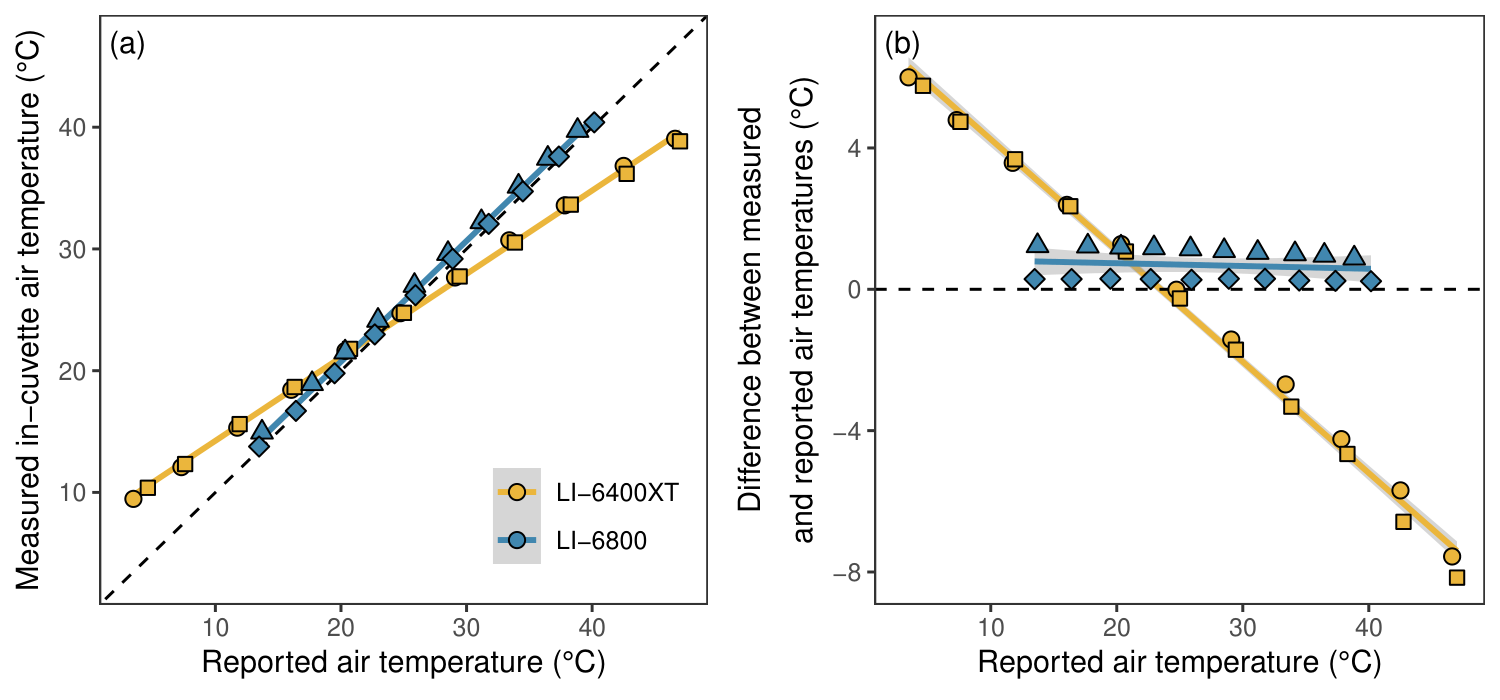

rendered /content/licor_rep/figures/fig5.png (111949 bytes)


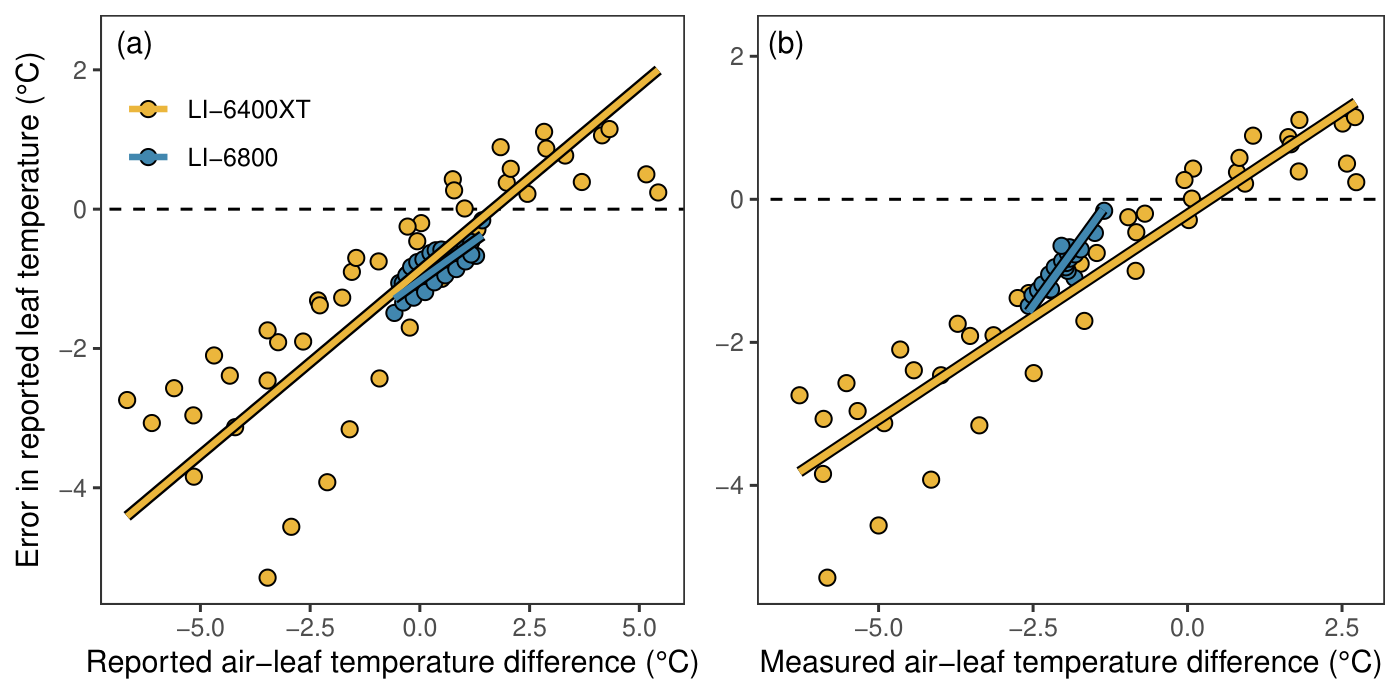

rendered /content/licor_rep/figures/fig6.png (102609 bytes)


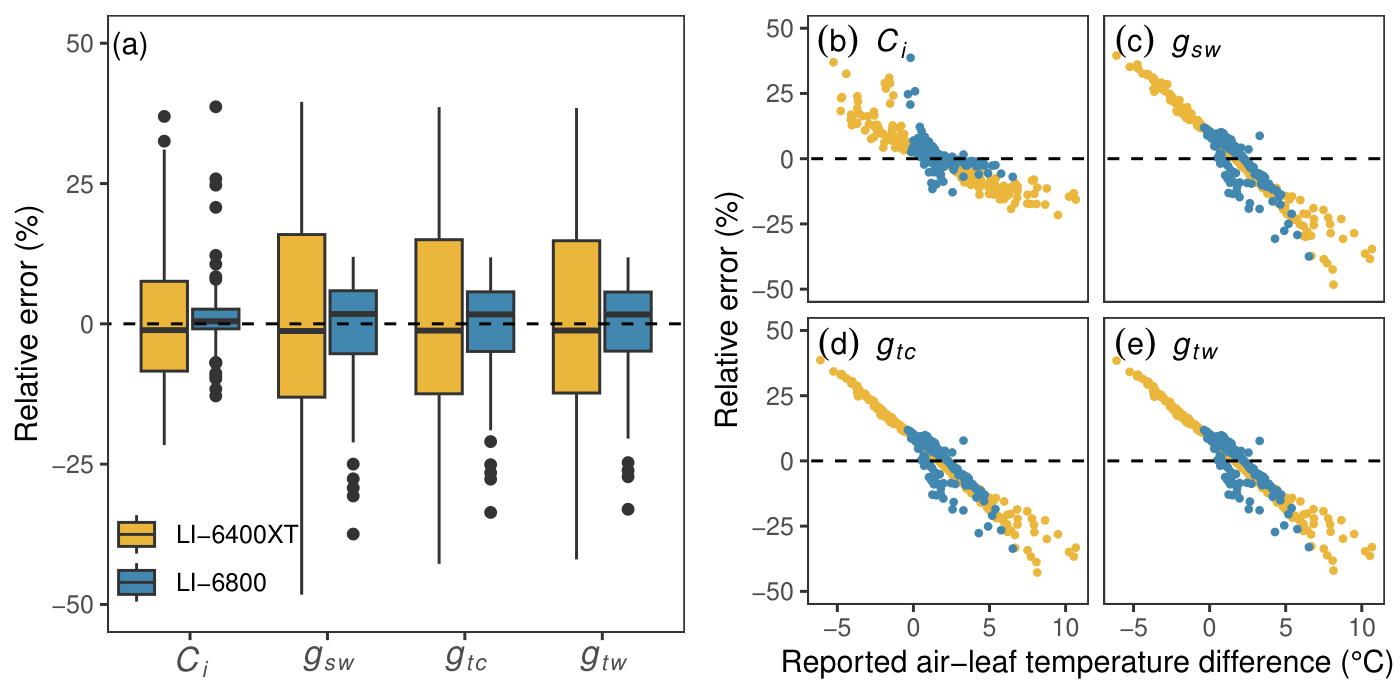

In [ ]:
try:
    import pymupdf
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pymupdf"])
    import pymupdf

from IPython.display import Image, display
for name in ["fig2", "fig5", "fig6"]:
    pdf_path = WORK / "figures" / f"{name}.pdf"
    png_path = WORK / "figures" / f"{name}.png"
    doc = pymupdf.open(pdf_path)
    doc[0].get_pixmap(dpi=200).save(png_path)
    doc.close()
    print(f"rendered {png_path} ({png_path.stat().st_size} bytes)")
    display(Image(filename=str(png_path)))

### 8. Temperature corrections: the authors' functions and their quantitative effect

Figure 6 already exercised the corrections internally. Here we print the two correction files (so the instrument-specific parameters embedded by the authors are visible: for the LI-6400XT, `correct_Tleaf6400` slope `0.52959` / intercept `−0.87710` on (Tair − Tleaf), and `correct_Tair6400` slope `2.28354` / intercept `−0.34569` on (Tblock − Tair)), then re-apply `correct_licor6400()` and `correct_licor6800()` and tabulate the **median relative error** per derived quantity — the same quantities as Fig. 6, as numbers. A small CSV export is written to the VM (`/content/licor_rep/derived_quantity_errors.csv`) for the learner.
**日本語:** 著者の補正関数（機器固有のパラメータ付き）を表示し、補正前後の派生量（g_sw, g_tw, g_tc, C_i）の相対誤差の中央値を表で出力します。CSV も書き出します。

In [ ]:
corr_driver = WORK / "correction_summary.R"
corr_driver.write_text(r"""
setwd("/content/licor_rep")
Sys.setlocale("LC_ALL", "C.UTF-8")
suppressPackageStartupMessages({ library(dplyr); library(LICOR6400) })
source("R/correct_licor6400.R")
source("R/correct_licor6800.R")

cat("----- R/correct_licor6400.R (authors' pinned version) -----\n")
cat(readLines("R/correct_licor6400.R"), sep = "\n")
cat("\n----- R/correct_licor6800.R (authors' pinned version) -----\n")
cat(readLines("R/correct_licor6800.R"), sep = "\n")

data6400 <- read.csv("data/error_propagation_6400.csv")
data6800 <- read.csv("data/error_propagation_6800.csv")
data6400$total.leaf.area <- data6400$chamber_leaf_area
data6400_corr <- correct_licor6400(data6400)
data6800_corr <- correct_licor6800(data6800)

mk <- function(uncorr, corr, cols, instrument) {
  do.call(rbind, lapply(cols, function(cc) {
    data.frame(instrument = instrument,
               variable = cc,
               relative_error = (uncorr[[cc]] - corr[[cc]]) / corr[[cc]],
               Tair = uncorr$Tair, Tleaf = uncorr$Tleaf)
  }))
}
error_all <- rbind(
  mk(data6400, data6400_corr, c("Cond", "CndTotal", "CndCO2", "Ci"), "LI-6400XT"),
  mk(data6800, data6800_corr, c("gsw", "gtw", "gtc", "Ci"), "LI-6800"))
error_all$variable <- recode(error_all$variable, Cond = "g_sw", CndTotal = "g_tw",
                             CndCO2 = "g_tc", gsw = "g_sw", gtw = "g_tw", gtc = "g_tc")
write.csv(error_all, "derived_quantity_errors.csv", row.names = FALSE)
cat("\nMedian relative error (%) of reported vs corrected derived quantities:\n")
print(with(error_all,
      tapply(100 * relative_error, list(instrument, variable), median)))
""")
r = run(["Rscript", str(corr_driver)], timeout=1200)
print(r.stdout)
if r.returncode != 0:
    print(r.stderr[-5000:]); raise RuntimeError("correction summary failed")

[1] "LC_CTYPE=C.UTF-8;LC_NUMERIC=C;LC_TIME=C.UTF-8;LC_COLLATE=C.UTF-8;LC_MONETARY=C.UTF-8;LC_MESSAGES=C.UTF-8;LC_PAPER=C.UTF-8;LC_NAME=C;LC_ADDRESS=C;LC_TELEPHONE=C;LC_MEASUREMENT=C.UTF-8;LC_IDENTIFICATION=C"
----- R/correct_licor6400.R (authors' pinned version) -----
# Gas exchange analyzers exhibit large errors driven by internal thermal gradients
# Josef Garen, Haley Branch, Isaac Borrego, Benjamin Blonder, Joseph Stinziano, and Sean Michaletz
# New Phytologist 2022
#
# Functions for correcting leaf and air temperatures in the LI-6400XT
#
# Last edited 13 July 2022, Josef Garen

# Function to correct Tleaf based on the difference between Tair and Tleaf
correct_Tleaf6400 = function(Tleaf, Tair, slope = 0.52959, intercept = -0.87710) {
  return(Tleaf - (slope*(Tair-Tleaf)+intercept))
}

# Function to correct Tair based on the difference between Tblock and Tair
correct_Tair6400 = function(Tblock, Tair, slope = 2.28354, intercept = -0.34569) {
    return(Tair - (slope*(Tblock-Tair)+inte

### 9. Interpretation, validation record and references

**What this run shows (from the actual outputs above):** the LI-6400XT's reported air temperature deviates strongly from the independently measured in-cuvette temperature (Fig. 2, empty chamber), the reported leaf temperature deviates from thermocouples placed above/below the leaf in a temperature-gradient-dependent way (Fig. 5, linear mixed models with a random intercept/slope per instrument unit), and applying the authors' embedded correction parameters shifts derived *g*<sub>sw</sub>, *g*<sub>tw</sub>, *g*<sub>tc</sub> and *C*<sub>i</sub> by the relative amounts summarised in §8 (Fig. 6). The LI-6800's errors are much smaller. The exact numbers are in the printed `stats.txt` and the displayed summaries — read them from the outputs, not from this text.

**Fidelity and limits:**
- The executed `make_fig*.R` and `correct_*.R` files are byte-verified unmodified author code at commit `15e005f…`; the driver only replicates the libraries, palettes, theme and call order of the authors' `R/analysis.R`.
- `correct_licor6400()` recalculates derived quantities with `LICOR6400::calc_licor()` (Telford, MIT, installed from GitHub) — a third-party dependency the authors' pipeline itself requires.
- One-example caveat does not apply (the authors' full released trial tables are used), but this remains a **partial reproduction**: Figs. 1, 3, 4, 7, 8, 9 and S1–S3 were not run; dataset-level claims (e.g. Vcmax 12 % / Jmax 35 %) were not re-derived here.
- The correction parameters are instrument- and condition-specific (the authors' own warning); do not apply them to other instruments without independent calibration.

**Validation record:** executed end-to-end on a fresh Colab **CPU** runtime on 2026-10-29; outputs archived from that run. The notebook detects the VM's Ubuntu codename to pick the matching Posit binary repository and fails loudly on any pinned-file integrity mismatch.

**References:**
- Garen, J. et al. (2022) *New Phytologist* 236(2):369–384. doi:[10.1111/nph.18347](https://doi.org/10.1111/nph.18347) (PMID 35762843).
- Code: `github.com/MichaletzLab/LI-COR-thermal-gradients` @ `15e005fd3797b087429b1ba79183362b4a5cba0e`.
- `LICOR6400`: `github.com/Plant-Functional-Trait-Course/LICOR6400` (MIT).

**日本語:** 本実行結果（上の出力そのもの）から、LI-6400XT は報告気温・葉温が実測温度から大きくずれ（Fig. 2・5）、著者の組込みパラメータによる補正で派生量に相対誤差が生じること（Fig. 6・§8）、LI-6800 の誤差がはるかに小さいことが確認できます。実行は 2026-10-29 に新しい Colab CPU ランタイムでトップダウンに行われました。Fig. 1, 3, 4, 7–9, S1–S3 は未実行の部分的な再現です。補正パラメータは機器・条件固有であり、他の機器への適用には独立した較正が必要です（著者の注意書き通り）。